In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
wr.filterwarnings('ignore')

df = pd.read_excel("medicamentos_epilepsia_HU3.xlsx")
df.describe().T

,count,mean,min,25%,50%,75%,max,std
nregistro,988.0,58003971.409919,3275.0,79409.75,84385.5,90361.25,1231732001.0,247256346.393465
cn,988.0,717489.643725,600014.0,693678.0,721201.0,758160.25,918839.0,47933.676533
estado_aut,988,2016-06-09 22:37:59.773279,1922-10-01 00:00:00,2012-10-29 23:00:00,2018-02-05 23:00:00,2022-03-21 23:37:05.500000,2026-08-28 15:52:00,NaN
estado_rev,143,2024-07-30 06:53:11.825174,2021-11-02 15:39:52,2023-02-03 11:05:00,2024-10-11 11:31:04,2026-03-02 15:50:40.500000,2026-09-16 07:51:13,NaN
comercializado,988.0,0.625506,0.0,0.0,1.0,1.0,1.0,0.484237
requiere_receta,988.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
generico,988.0,0.860324,0.0,1.0,1.0,1.0,1.0,0.346826
afecta_conduccion,988.0,0.986842,0.0,1.0,1.0,1.0,1.0,0.114008
triangulo_negro,988.0,0.009109,0.0,0.0,0.0,0.0,1.0,0.095055
medicamento_huerfano,988.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [235]:
df.describe(include='object').T

,count,unique,top,freq
nombre,988,971,KEPPRA 100 mg/ml SOLUCION ORAL,3
pactivos,988,29,PREGABALINA,242
labtitular,988,103,Laboratorios Combix S.L.U.,56
labcomercializador,988,92,Teva Pharma S.L.U.,62
dosis,988,126,100 mg,101
forma_farmaceutica_simplificada,988,11,COMPRIMIDO,510
vias_administracion,988,4,VÍA ORAL,941
url_html_ficha_tecnica,988,988,https://cima.aemps.es/cima/dochtml/ft/62620/FT...,1
url_foto_materiales,192,192,https://cima.aemps.es/cima/fotos/thumbnails/ma...,1
Estado,584,4,ALTA,475


In [236]:
print('Filas duplicadas:', df.duplicated().sum())

Filas duplicadas: 0


<Axes: >

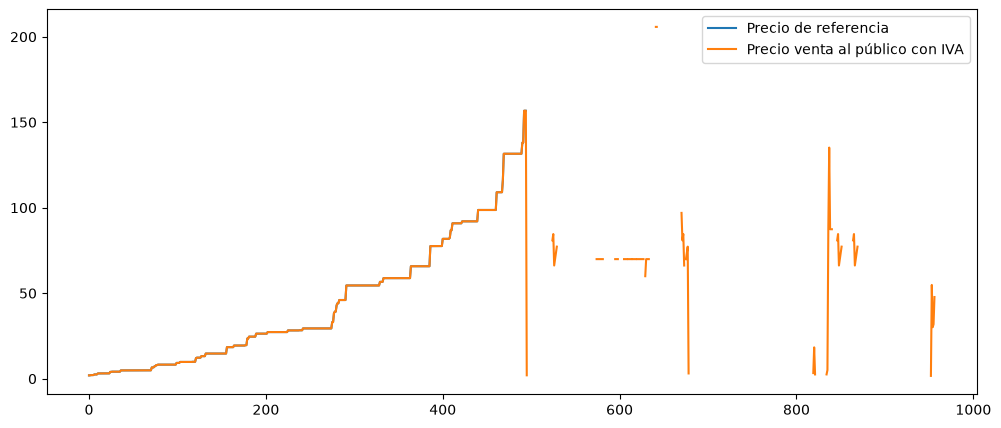

In [237]:
df[["Precio de referencia", "Precio venta al público con IVA"]].sort_values("Precio de referencia").reset_index(drop=True).plot(figsize=(12, 5))


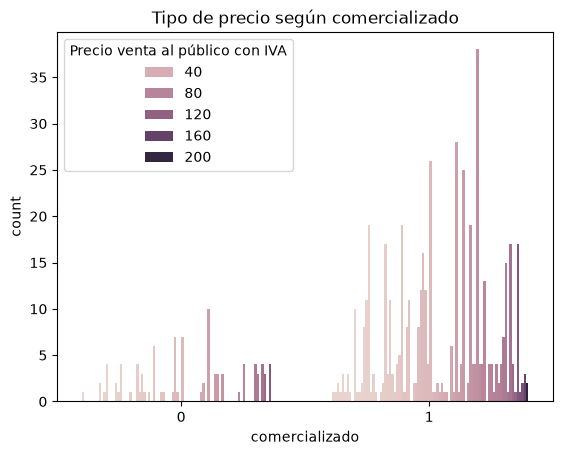

In [238]:
sns.countplot(data=df, x="comercializado", hue="Precio venta al público con IVA")
plt.title("Tipo de precio según comercializado")
plt.show() #no tiene ninguna relaciob, como vemos en la grafica hay precios con y sin comercializado, por lo que no tiene sentido eliminarlo, ya que no hay una relación entre comercializado y precio. Seran precios históricos

In [239]:
df.isnull().sum()

nregistro                                            0
nombre                                               0
pactivos                                             0
labtitular                                           0
labcomercializador                                   0
cn                                                   0
dosis                                                0
forma_farmaceutica_simplificada                      0
estado_aut                                           0
estado_rev                                         845
vias_administracion                                  0
comercializado                                       0
requiere_receta                                      0
generico                                             0
afecta_conduccion                                    0
triangulo_negro                                      0
medicamento_huerfano                                 0
biosimilar                                           0
url_html_f

DADO QUE NO HAY CORRELACIÓN ENTRE COMERCIALIZADO Y PRECIO VENTA CON IVA, ELIMINAMOS LAS FILAS QUE NO TIENEN PRECIO, YA QUE OTRA SOLUCIÓN AFECTARÍA A LAS AGRUPACIONES DEL MODELO FUTURO, un mismo principio activo puede costar desde unos pocos euros hasta más de 100 € (zonisamida va de 4,80 € a 116,30 €). Por eso no se puede inventar el precio.

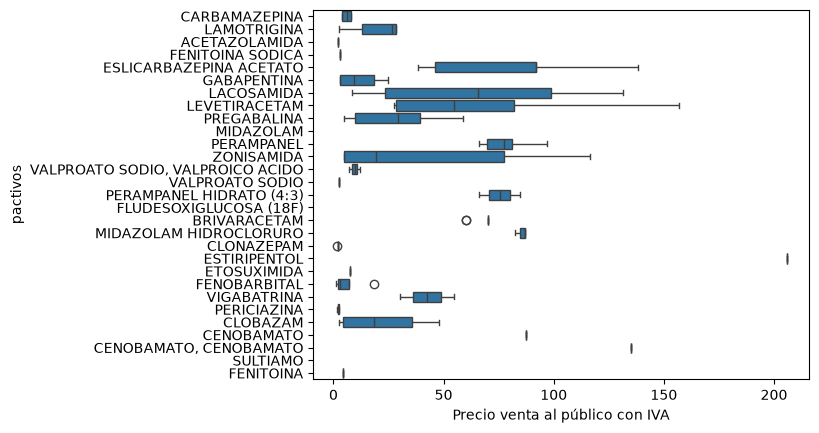

In [240]:
sns.boxplot(data=df, x='Precio venta al público con IVA', y='pactivos')
plt.show()

In [241]:
df = df.drop(columns=["Precio venta al público con IVA"])  #eliminamos por tanto esas filas

In [242]:
#LOS DOS PRECIOS SON IGUALES MENOS EN POCOS CASOS QUE REFERENCIA NO TIENE VALOR, POR LO QUE ELIMINAMOS
#PRECIO REFERENCIA
df = df.drop(columns=['Precio de referencia'])

ELIMINAMOS COLUMNAS QUE NO INTERESAN

In [243]:
df = df.drop(columns=['nregistro','cn','estado_rev', 'estado_aut', 'url_html_ficha_tecnica', 'url_foto_materiales'])
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis,forma_farmaceutica_simplificada,vias_administracion,comercializado,requiere_receta,generico,...,biosimilar,num_registros_atc,num_principios_activos,num_excipientes,Volumen Informativo de Seguridad (num palabras),Complejidad del Desglose Clínico (num tablas),Indicador de Riesgo Severo (num veces grave/s),Estado,Tratamiento de larga duración,Especial control médico
0,CARBAMAZEPINA NORMON 200 mg COMPRIMIDOS EFG,CARBAMAZEPINA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,200 mg carbamazepina,COMPRIMIDO,VÍA ORAL,1,1,1,...,0,3,1,0,2558,0,16,ALTA,SI,NO
1,CARBAMAZEPINA NORMON 400 mg COMPRIMIDOS EFG,CARBAMAZEPINA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,400 mg carbamazepina,COMPRIMIDO,VÍA ORAL,1,1,1,...,0,3,1,0,2558,0,16,ALTA,SI,NO
2,CRISOMET 100 mg COMPRIMIDOS MASTICABLES/DISPER...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,100 mg lamotrigina,COMPRIMIDO MASTICABLE,VÍA ORAL,1,1,0,...,0,3,1,0,2420,8,16,BAJA POR NO COMERCIALIZAR,SI,NO
3,CRISOMET 200 mg COMPRIMIDOS MASTICABLES/DISPER...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,200 mg lamotrigina,COMPRIMIDO MASTICABLE,VÍA ORAL,1,1,0,...,0,3,1,0,2420,8,16,BAJA POR NO COMERCIALIZAR,SI,NO
4,CRISOMET 25 mg COMPRIMIDOS MASTICABLES/DISPERS...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,25 mg lamotrigina,COMPRIMIDO MASTICABLE,VÍA ORAL,1,1,0,...,0,3,1,0,2420,8,16,BAJA POR NO COMERCIALIZAR,SI,NO


ELIMINAMOS COLUMNAS QUE SONO CONSTANTES, NO APORTAN NADA A NUESTRO FUTURO MODELO


In [244]:
df = df.drop(columns=['requiere_receta', 'medicamento_huerfano', 'biosimilar', 'num_registros_atc', 'num_excipientes', 'Especial control médico'])

In [247]:
df.duplicated().sum()
df[df.duplicated(keep=False)].sort_values('nombre')

,nombre,pactivos,labtitular,labcomercializador,dosis,comercializado,generico,afecta_conduccion,triangulo_negro,num_principios_activos,...,forma_farmaceutica_simplificada_COMPRIMIDO MASTICABLE,forma_farmaceutica_simplificada_GEL/PASTA/LIQUIDO BUCAL,forma_farmaceutica_simplificada_INYECTABLE,forma_farmaceutica_simplificada_INYECTABLE PERFUSION,forma_farmaceutica_simplificada_SOLUCION/SUSPENSION GOTAS ORALES,forma_farmaceutica_simplificada_SOLUCIÓN/SUSPENSIÓN ORAL,vias_administracion_VÍA INTRAMUSCULAR,vias_administracion_VÍA INTRAVENOSA,vias_administracion_VÍA ORAL,vias_administracion_Vía bucal (buccal use)
417,KEPPRA 100 mg/ml SOLUCION ORAL,LEVETIRACETAM,Ucb Pharma,Ucb Pharma S.A.,100 mg/ml de Levetiracetam,1,0,1,0,1,...,0,0,0,0,0,1,0,0,1,0
418,KEPPRA 100 mg/ml SOLUCION ORAL,LEVETIRACETAM,Ucb Pharma,Ucb Pharma S.A.,100 mg/ml de Levetiracetam,1,0,1,0,1,...,0,0,0,0,0,1,0,0,1,0
83,LEVETIRACETAM HOSPIRA 100 MG/ML CONCENTRADO PA...,LEVETIRACETAM,Pfizer Europe Ma Eeig,Pfizer S.L.,100 mg/ml,0,1,1,0,1,...,0,0,0,1,0,0,0,1,0,0
609,LEVETIRACETAM HOSPIRA 100 MG/ML CONCENTRADO PA...,LEVETIRACETAM,Pfizer Europe Ma Eeig,Pfizer S.L.,100 mg/ml,0,1,1,0,1,...,0,0,0,1,0,0,0,1,0,0
638,LEVETIRACETAM RATIOPHARM 100 MG/ML SOLUCION OR...,LEVETIRACETAM,Ratiopharm Gmbh,Teva Pharma S.L.U.,100 mg levetiracetam/ml,0,1,1,0,1,...,0,0,0,0,0,1,0,0,1,0
639,LEVETIRACETAM RATIOPHARM 100 MG/ML SOLUCION OR...,LEVETIRACETAM,Ratiopharm Gmbh,Teva Pharma S.L.U.,100 mg levetiracetam/ml,0,1,1,0,1,...,0,0,0,0,0,1,0,0,1,0


In [249]:
df = df.drop_duplicates()

Eliminamos duplicados ya que para el análisis aportan exactamente la misma información, y repetidos pesan el doble en las estadísticas y en el K-Means.

Pasamos las categóricas a números

In [246]:
df = pd.get_dummies(df, columns=['forma_farmaceutica_simplificada', 'vias_administracion'], dtype=int)
df.head()

,nombre,pactivos,labtitular,labcomercializador,dosis,comercializado,generico,afecta_conduccion,triangulo_negro,num_principios_activos,...,forma_farmaceutica_simplificada_COMPRIMIDO MASTICABLE,forma_farmaceutica_simplificada_GEL/PASTA/LIQUIDO BUCAL,forma_farmaceutica_simplificada_INYECTABLE,forma_farmaceutica_simplificada_INYECTABLE PERFUSION,forma_farmaceutica_simplificada_SOLUCION/SUSPENSION GOTAS ORALES,forma_farmaceutica_simplificada_SOLUCIÓN/SUSPENSIÓN ORAL,vias_administracion_VÍA INTRAMUSCULAR,vias_administracion_VÍA INTRAVENOSA,vias_administracion_VÍA ORAL,vias_administracion_Vía bucal (buccal use)
0,CARBAMAZEPINA NORMON 200 mg COMPRIMIDOS EFG,CARBAMAZEPINA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,200 mg carbamazepina,1,1,1,0,1,...,0,0,0,0,0,0,0,0,1,0
1,CARBAMAZEPINA NORMON 400 mg COMPRIMIDOS EFG,CARBAMAZEPINA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,400 mg carbamazepina,1,1,1,0,1,...,0,0,0,0,0,0,0,0,1,0
2,CRISOMET 100 mg COMPRIMIDOS MASTICABLES/DISPER...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,100 mg lamotrigina,1,0,1,0,1,...,1,0,0,0,0,0,0,0,1,0
3,CRISOMET 200 mg COMPRIMIDOS MASTICABLES/DISPER...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,200 mg lamotrigina,1,0,1,0,1,...,1,0,0,0,0,0,0,0,1,0
4,CRISOMET 25 mg COMPRIMIDOS MASTICABLES/DISPERS...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,25 mg lamotrigina,1,0,1,0,1,...,1,0,0,0,0,0,0,0,1,0


Finalmente guardamos el resultado de todo el EDA

In [250]:
df.to_csv('medicamentos_epilepsia_HU4_limpio.csv', index=False)